# Separate the rate and volatility drivers of option value

**Question.** How does a receive-fixed swap respond differently from a caplet
when deposit/OIS rates rise 10 bp or Black volatilities rise one point?

Use the illustrative 24 February 2026 USD/SOFR single-curve market, USD 1 million
positions and a 4.5% strike caplet expiring in two years. Rates and strikes are
decimals. Only the caplet uses the Black surface. Each stress changes input
quotes **before** rebuilding dependent market objects; it is not a direct
zero-rate or discount-factor shift. No realized-rate forecast is implied.
[Setup](../README.md).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market

market = load_market()
ref = market.quotes.reference_date


## Construction specifications tell the context what to build

Here is the actual SOFR bootstrap specification loaded by the helper. Its
`quotes` list identifies the deposit/OIS instruments that constrain the curve.
The interpolation and day-count conventions govern values between pillars.
`from_dict` also lets you construct an editable configuration in memory;
`from_json` is useful for larger input sets.

The surface specification identifies caplet Black-volatility quotes. We keep
the long list of market identifiers in the auxiliary data and use typed enums
for the conventions we want to highlight.

In [2]:
curve_spec = market.curves[0].to_dict()
curve_config = qs.CurveConfiguration.from_dict(curve_spec)
surface_spec = market.volatility_surfaces[0].to_dict()
surface_config = qs.VolatilitySurfaceConfiguration.from_dict(
    {
        **surface_spec,
        "market_index": qs.MarketIndex.SOFR,
        "volatility_type": qs.VolatilityType.Black,
        "smile_type": qs.SmileType.Strike,
    }
)
print(
    "Curve conventions:",
    {key: value for key, value in curve_spec.items() if key != "quotes"},
)
print(
    "Surface conventions:",
    {key: value for key, value in surface_spec.items() if key != "quotes"},
)
print(
    "Curve quotes:",
    len(curve_spec["quotes"]),
    "| Volatility quotes:",
    len(surface_spec["quotes"]),
)


Curve conventions: {'market_index': 'SOFR', 'construction': {'type': 'Bootstrapped'}, 'day_counter': 'Actual360', 'interpolator': 'LogLinear', 'enable_extrapolation': True}
Surface conventions: {'market_index': 'SOFR', 'volatility_type': 'Black', 'smile_type': 'Strike', 'extrapolation_policy': 'Reject'}
Curve quotes: 8 | Volatility quotes: 27


## Observe nodes, forwards, and the smile

Query the constructed objects inside an active context. `nodes()` returns
dated discount factors; `pillars()` returns labels used to trace risk back to
inputs. A forward rate is inferred from discount factors over the requested
interval under the selected compounding convention.

This surface's smile coordinate is an **absolute strike**, so `0.045` means a
4.5% strike, not a delta or log-moneyness. Its values are decimal Black vols.
The grid below stays within the supplied quote domain and includes an
intermediate strike so the interpolation is visible.

In [3]:
expiries = ["6M", "1Y", "2Y", "3Y", "5Y", "7Y"]
strikes = [0.035, 0.040, 0.045, 0.050, 0.055]
context = qs.PricingContext(
    quotes=market.quotes,
    curves=[curve_config],
    csa_policy=market.csa_policy,
    volatility_surfaces=[surface_config],
)

with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    surface = context.volatility_surface(qs.MarketIndex.SOFR)
    nodes = curve.nodes()
    pillars = curve.pillars()
    forwards = pd.DataFrame(
        [
            {
                "start": tenor,
                "discount_factor": curve.discount_factor(ref + tenor),
                "one_year_forward": curve.forward_rate(
                    ref + tenor,
                    ref + tenor + "1Y",
                    qs.Compounding.Simple,
                    qs.Frequency.Annual,
                ),
            }
            for tenor in ["1Y", "2Y", "3Y", "5Y", "7Y"]
        ]
    )
    smile = pd.DataFrame(
        {
            expiry: [
                surface.volatility(
                    expiry,
                    strike,
                )
                for strike in strikes
            ]
            for expiry in expiries
        },
        index=pd.Index(
            strikes,
            name="strike",
        ),
    )
    print(
        surface.volatility_type,
        surface.smile_type,
    )

forwards


Black Strike


,start,discount_factor,one_year_forward
0,1Y,0.953257,0.042106
1,2Y,0.914227,0.036951
2,3Y,0.881127,0.037741
3,5Y,0.817367,0.039061
4,7Y,0.756187,0.035225


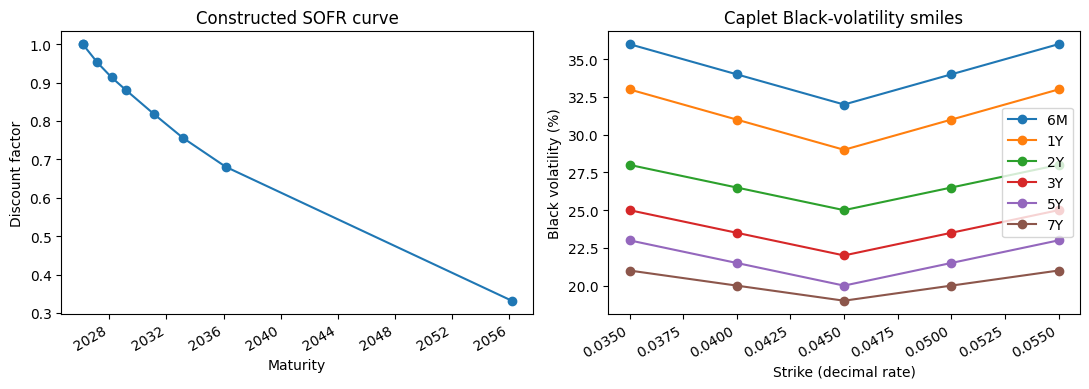

In [4]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
)
axes[0].plot(
    pd.to_datetime(nodes["date"]),
    nodes["discount_factor"],
    marker="o",
)
axes[0].set(
    title="Constructed SOFR curve",
    xlabel="Maturity",
    ylabel="Discount factor",
)
(smile * 100).plot(
    ax=axes[1],
    marker="o",
)
axes[1].set(
    title="Caplet Black-volatility smiles",
    xlabel="Strike (decimal rate)",
    ylabel="Black volatility (%)",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Revalue the same contracts under changed inputs

A `Scenario` shocks quote values **before** construction. The market view builds
the dependent curve or surface; it does not add a bump directly to each
discount factor. This distinction preserves the meaning of a market-quote
stress.

Scenario selectors match underscore-delimited identifier segments. `SOFR`
would match both OIS rates and SOFR caplet vols in this snapshot. We therefore
use the curve quote IDs for a parallel rate-quote bump and one unambiguous caplet-family selector for the volatility bump. Targets match sets of underscore-separated segments, so even full IDs can overlap (the repeated `3M` in a 3M-tenor/3M-expiry label does not constrain another expiry). Enumerating every volatility ID would therefore double-shock some quotes. `Absolute` adds the number; `Relative` would
multiply by `1 + shock`.

In [5]:
swap = qs.Swap(
    identifier="SWAP",
    start_date=ref,
    maturity_date=ref + "5Y",
    notional=1_000_000,
    fixed_rate=0.04,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
)
caplet = qs.CapletFloorlet(
    identifier="CAPLET",
    fixing_date=ref + "2Y",
    start_accrual_date=ref + "2Y",
    end_accrual_date=ref + "2Y3M",
    payment_date=ref + "2Y3M",
    strike=0.045,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
    payoff_type=qs.CapletFloorletType.Caplet,
)
swap_trade = qs.Trade(swap, ref)
caplet_trade = qs.Trade(caplet, ref, notional=1_000_000)
rate_up = [
    qs.Shock(target=label, value=0.001, shock_type=qs.ScenarioType.Absolute)
    for label in curve_spec["quotes"]
]
vol_up = [
    qs.Shock(target="CapletFloorlet_USD_SOFR", value=0.01, shock_type=qs.ScenarioType.Absolute)
]


def observe_market(scenarios):
    context = qs.PricingContext(
        quotes=market.quotes,
        curves=[curve_config],
        csa_policy=market.csa_policy,
        volatility_surfaces=[surface_config],
    )

    with context, qs.Scenario(shocks=scenarios):
        return {
            "swap_pv_usd": context.evaluate(swap_trade).price,
            "caplet_pv_usd": context.evaluate(caplet_trade).price,
            "five_year_df": context.curve(qs.MarketIndex.SOFR).discount_factor(
                ref + "5Y"
            ),
            "two_year_vol": context.volatility_surface(qs.MarketIndex.SOFR).volatility(
                "2Y",
                0.045,
            ),
        }


comparison = pd.DataFrame(
    {
        "base": observe_market([]),
        "rates +10 bp": observe_market(rate_up),
        "vols +1 point": observe_market(vol_up),
    }
).T
comparison["swap_pnl_usd"] = (
    comparison["swap_pv_usd"] - comparison.loc["base", "swap_pv_usd"]
)
comparison["caplet_pnl_usd"] = (
    comparison["caplet_pv_usd"] - comparison.loc["base", "caplet_pv_usd"]
)
comparison

,swap_pv_usd,caplet_pv_usd,five_year_df,two_year_vol,swap_pnl_usd,caplet_pnl_usd
base,-1664.892276,571.899568,0.817367,0.25,0.000000,0.000000
rates +10 bp,-6081.722671,649.084288,0.813418,0.25,-4416.830395,77.184721
vols +1 point,-1664.892276,615.801139,0.817367,0.26,0.000000,43.901571


For this receive-fixed swap, higher rate quotes reduce PV. A volatility-only
move leaves its value unchanged because its pricer does not use a volatility
surface. Higher Black volatility increases the long caplet's option value.
The caplet's response to rates combines a change in its forward with a change
in discounting; do not interpret it as a pure discount-factor effect.

The table and plot show the economic effects of each market shock.

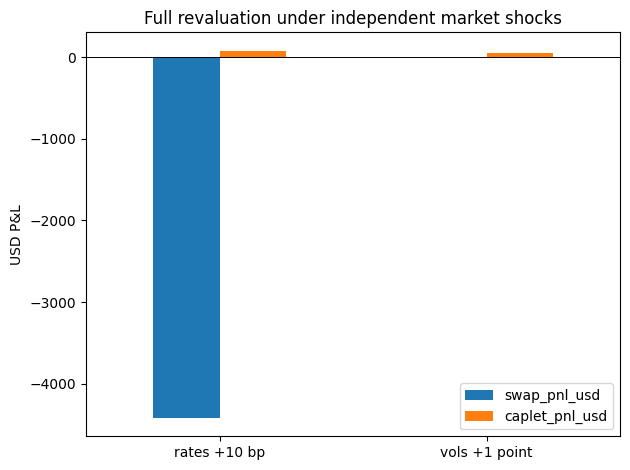

In [6]:
comparison[["swap_pnl_usd", "caplet_pnl_usd"]].iloc[1:].plot.bar(
    title="Full revaluation under independent market shocks",
    ylabel="USD P&L",
    rot=0,
)
plt.axhline(
    0,
    color="black",
    linewidth=0.7,
)
plt.tight_layout()
plt.show()


## Check interpolation and isolate each channel

At a quoted expiry and between adjacent strikes, the configured smile is
linear: $\sigma(K)=(1-w)\sigma(K_0)+w\sigma(K_1)$, where
$w=(K-K_0)/(K_1-K_0)$. This checks interpolation in volatility, not in option
price or total variance. Outside-domain behavior is a separate configured
choice; we deliberately stay inside the available grid.


In [7]:
import math

quotes = market.quotes.to_dataframe().set_index("identifier")["mid"]
low_label = "CapletFloorlet_USD_SOFR_3M_2Y_Absolute_0.035_Straddle_Black"
high_label = "CapletFloorlet_USD_SOFR_3M_2Y_Absolute_0.045_Straddle_Black"
interpolated_vol = (quotes.loc[low_label] + quotes.loc[high_label]) / 2
assert math.isclose(smile.loc[0.040, "2Y"], interpolated_vol, abs_tol=1e-12)
with context, qs.Scenario(shocks=vol_up):
    bumped_quotes = context.quotes.to_dataframe().set_index("identifier")["mid"]
quote_moves = bumped_quotes - quotes
assert quote_moves.loc[surface_spec["quotes"]].sub(0.01).abs().max() < 1e-12
assert quote_moves.loc[curve_spec["quotes"]].abs().max() < 1e-12
assert math.isclose(
    comparison.loc["vols +1 point", "swap_pv_usd"],
    comparison.loc["base", "swap_pv_usd"], abs_tol=1e-7,
)
assert comparison.loc["rates +10 bp", "swap_pnl_usd"] < 0
assert comparison.loc["vols +1 point", "caplet_pnl_usd"] > 0
assert math.isclose(
    comparison.loc["vols +1 point", "two_year_vol"]
    - comparison.loc["base", "two_year_vol"], 0.01, abs_tol=1e-12,
)
assert math.isclose(
    comparison.loc["rates +10 bp", "two_year_vol"],
    comparison.loc["base", "two_year_vol"], abs_tol=1e-12,
)
assert math.isclose(
    comparison.loc["vols +1 point", "five_year_df"],
    comparison.loc["base", "five_year_df"], abs_tol=1e-12,
)
print(f"Interpolated 2Y Black vol at 4% strike: {interpolated_vol:.2%}.")
print("Independent shocks leave the unrelated market object unchanged.")
comparison[["swap_pnl_usd", "caplet_pnl_usd", "five_year_df", "two_year_vol"]]


Interpolated 2Y Black vol at 4% strike: 26.50%.
Independent shocks leave the unrelated market object unchanged.


,swap_pnl_usd,caplet_pnl_usd,five_year_df,two_year_vol
base,0.000000,0.000000,0.817367,0.25
rates +10 bp,-4416.830395,77.184721,0.813418,0.25
vols +1 point,0.000000,43.901571,0.817367,0.26


## Conclusion

The swap loses value when the fixed coupon becomes less competitive, but has
zero volatility-only P&L. The caplet benefits from higher volatility. Its
rate-shock P&L combines forward and discount effects, so it is not simply a
bond-duration calculation. These are full finite-move revaluations; local
quote derivatives provide a separate approximation checked in the risk study.


For local risk, [portfolio_risk.ipynb](../sensitivity/portfolio_risk.ipynb) compares quote
derivatives with small full-revaluation bumps. For callable bonds or simulated
rates, the surface instead calibrates a short-rate model: its Black quotes are
not the model's absolute short-rate sigma. Follow that extra construction step
in [simulations](../hullwhite/simulations.ipynb) and [stepped bonds](../valuation/bonds/stepped_coupon_bond.ipynb).